In [7]:
! pip install langgraph==0.3.34 langchain-core==0.3.72

  Using cached langgraph-0.3.34-py3-none-any.whl.metadata (7.9 kB)
  Using cached langchain_core-0.3.72-py3-none-any.whl.metadata (5.8 kB)
Using cached langchain_core-0.3.72-py3-none-any.whl (442 kB)
  Attempting uninstall: xxhash
    Found existing installation: xxhash 4.1.0
    Uninstalling xxhash-4.1.0:
      Successfully uninstalled xxhash-4.1.0
  Attempting uninstall: langgraph-sdk
    Found existing installation: langgraph-sdk 0.4.14
    Uninstalling langgraph-sdk-0.4.14:
      Successfully uninstalled langgraph-sdk-0.4.14
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.7
    Uninstalling langchain-core-1.7.7:
      Successfully uninstalled langchain-core-1.7.7
  Attempting uninstall: langgraph-checkpoint━━━━━━━━━━━━━━━━━━━━━━ 2/6 [langchain-core]
    Found existing installation: langgraph-checkpoint 4.3.1━━━ 2/6 [langchain-core]
    Uninstalling langgraph-checkpoint-4.3.1:━━━━━━━━━━━━━━━━━━ 2/6 [langchain-core]
      Successfully uninst

In [1]:
import sys
print(sys.executable)
print(sys.version)

/usr/local/src/myWork/AGENTIC_AI_STUDY/CHATBOT_STUDY/venv/bin/python
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:16:10) [GCC 11.2.0]


In [2]:
%pip uninstall -y langchain langchain-core langchain-openai langgraph langgraph-checkpoint

Found existing installation: langchain 0.3.27
Uninstalling langchain-0.3.27:
  Successfully uninstalled langchain-0.3.27
Found existing installation: langchain-core 0.3.72
Uninstalling langchain-core-0.3.72:
  Successfully uninstalled langchain-core-0.3.72
Found existing installation: langchain-openai 1.7.4
Uninstalling langchain-openai-1.7.4:
  Successfully uninstalled langchain-openai-1.7.4
Found existing installation: langgraph 0.3.34
Uninstalling langgraph-0.3.34:
  Successfully uninstalled langgraph-0.3.34
Found existing installation: langgraph-checkpoint 2.1.2
Uninstalling langgraph-checkpoint-2.1.2:
  Successfully uninstalled langgraph-checkpoint-2.1.2
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install langgraph==0.3.34 langchain-core==0.3.72 langchain-openai==0.3.28

  Using cached langgraph-0.3.34-py3-none-any.whl.metadata (7.9 kB)
  Using cached langchain_core-0.3.72-py3-none-any.whl.metadata (5.8 kB)
  Using cached langchain_openai-0.3.28-py3-none-any.whl.metadata (2.3 kB)
  Using cached langgraph_checkpoint-2.1.2-py3-none-any.whl.metadata (4.2 kB)
Using cached langgraph-0.3.34-py3-none-any.whl (148 kB)
Using cached langchain_core-0.3.72-py3-none-any.whl (442 kB)
Using cached langchain_openai-0.3.28-py3-none-any.whl (70 kB)
Using cached langgraph_checkpoint-2.1.2-py3-none-any.whl (45 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.6/948.6 kB 585.5 kB/s  0:00:01eta 0:00:01
  Attempting uninstall: openai
    Found existing installation: openai 3.49.0
    Uninstalling openai-3.49.0:
      Successfully uninstalled openai-3.49.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [langgraph]/5 [langgraph]openai]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of t

In [1]:
from typing import Annotated

from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, AIMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage

In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI(model="gpt-4.1-mini")

In [4]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [13]:
def chat_node(state: ChatState):

    decision = interrupt({
        "type": "approval",
        "reason": "Model is about to answer a user question.",
        "question": state["messages"][-1].content,
        "instruction": "Approve this question? yes/no"
    })

    if decision["approved"] == "no":
        return {
            "messages": [AIMessage(content="Not approved.")]
        }

    response = llm.invoke(state["messages"])

    return {
        "messages": [response]
    }

In [15]:
# 3. Build the graph: START -> chat -> END
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)

builder.add_edge(START, "chat")
builder.add_edge("chat", END)

# Checkpointer is required for interrupts
checkpointer = MemorySaver()

# Compile the app
app = builder.compile(checkpointer=checkpointer)

In [20]:
# Create a new thread id for this conversation
config = {"configurable": {"thread_id": '1234'}}

# ---- STEP 1: user asks a question ----
initial_input = {
    "messages": [
        ("user", "Explain gradient descent in very simple terms.")
    ]
}

# Invoke the graph for the first time
result = app.invoke(initial_input, config=config)

In [19]:
# Create a new thread id for this conversation
config = {"configurable": {"thread_id": '1234'}}

# ---- STEP 1: user asks a question ----
initial_input = {
    "messages": [
        ("user", "Explain gradient descent in very simple terms.")
    ]
}

# Invoke the graph for the first time
result = app.invoke(initial_input, config=config)

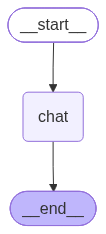

In [16]:
a

In [10]:
# Create a new thread id for this conversation
config = {"configurable": {"thread_id": '1234'}}

# ---- STEP 1: user asks a question ----
initial_input = {
    "messages": [
        ("user", "Explain gradient descent in very simple terms.")
    ]
}

# Invoke the graph for the first time
result = app.invoke(initial_input, config=config)

In [11]:
result

{'messages': [HumanMessage(content='Explain gradient descent in very simple terms.', additional_kwargs={}, response_metadata={}, id='3de4b883-7db0-423a-93cc-46ed3b1ad016'),
  HumanMessage(content='Explain gradient descent in very simple terms.', additional_kwargs={}, response_metadata={}, id='2e096b1b-c0f5-420b-a671-f2fba05093fd')]}

In [12]:
message = result['__interrupt__'][0].value
message

KeyError: '__interrupt__'